# Module 07 — LSTM (gates · the cell · the constant error carousel · gate biases)

Module 06 ended on a wall. The gradient through a recurrent network is a power of one matrix, so it
fades geometrically as it travels back in time, and a network learns to remember only as far back as
that gradient reaches. Bengio, Simard and Frasconi had proved in 1994 that tuning will not fix it: a
recurrent net that stores information *robustly* is one whose gradients from the past vanish.

In 1997 Sepp Hochreiter — whose 1991 diploma thesis had first analysed the problem — and Jürgen
Schmidhuber published the fix: **long short-term memory**. Give the network a second state, the
**cell**, that is not rewritten at every step but *added to*, under multiplicative **gates** that
decide what to write, what to keep and what to show. Along the cell the gradient is multiplied, step
after step, by a number the network chooses — and if it chooses one, the error rides back any
distance unchanged. They called it the **constant error carousel**.

This notebook builds the LSTM layer (forward, backpropagation through time along both of its paths,
chunked truncation, and Hochreiter and Schmidhuber's own cell-only gradient), which joins `nanograd`
in both languages. A toy that measures nothing but memory — the **latch**: a signal, $T-1$
distractors, then the question — shows what the gates buy and on what condition: the cell has to
start out open to the past and shut to new input. Then the 1997 gradient alone, a look inside the
trained cell, a character-level LSTM of Shakespeare against Module 06's RNN at the same budget, and
the framework mirrors.

In [1]:
import os, sys, math, time
# Windows + conda: conda's MKL (via LLVM OpenMP) and pip's PyTorch each bring
# an OpenMP runtime, and two in one process crash whichever loads first.
# Running MKL single-threaded keeps it from loading one at all; the long
# character-level training here is cached, and the toy sweeps run in a pool of
# worker processes instead. (A no-op wherever NumPy uses OpenBLAS.)
os.environ.setdefault('MKL_THREADING_LAYER', 'SEQUENTIAL')
import numpy as np
import matplotlib.pyplot as plt

# Locate the repo root whether Jupyter was launched from it or the module folder.
def _find_repo():
    here = os.getcwd()
    cands = [here] + [os.path.abspath(os.path.join(here, *(['..'] * k))) for k in range(1, 6)]
    for base in cands:
        if os.path.isdir(os.path.join(base, 'lib', 'python', 'nanograd')):
            return base
    return here

REPO = _find_repo()
TOPIC = os.path.join(REPO, 'topics', '07-lstm')
sys.path.insert(0, os.path.join(REPO, 'lib', 'python'))   # nanograd
sys.path.insert(0, os.path.join(TOPIC, 'python'))          # canonical lstm.py
sys.path.insert(0, os.path.join(TOPIC, 'tests'))           # check_utils

import nanograd as ng
import lstm as canon
m06 = canon.m06                                            # Module 06's canonical rnn.py
from nanograd.rng import Rng
from check_utils import rel_error, eval_numerical_gradient_array
np.set_printoptions(precision=4, suppress=True)
SYM = canon.SIGNALS + canon.DISTRACTORS                    # 'ABCDwxyz': signals, then distractors
print('new in nanograd:', ['LSTM'], '+ LSTM.backward(dH, truncate=k, cell_only=...), LSTM.gate_bias()')

new in nanograd: ['LSTM'] + LSTM.backward(dH, truncate=k, cell_only=...), LSTM.gate_bias()


## 1. The latch: Module 06's wall, measured

Module 06's echo asked a network to remember $d$ symbols at once, so its limit mixed two things:
how far back the gradient reaches, and how much a 16-unit state can hold. This module's toy
removes the second. A **signal** — one of `A B C D` — arrives at step 0; then come $T-1$
**distractors**, random symbols from `w x y z`; at the last step the network must say which signal
it saw. Holding one symbol out of four takes two bits, whatever $T$ is. What grows with $T$ is the
distance the lesson "keep that symbol" has to travel back: the only error signal is at step $T-1$,
and the moment of keeping is step 0.

Bengio, Simard and Frasconi (1994) called this ability *information latching*; it is, in miniature,
task 2c of Hochreiter and Schmidhuber's 1997 paper (a signal, hundreds of distractors, then the
question). Module 06's RNN, trained with full backpropagation through time:

one latch sequence, T = 24:   B yyxxwwwwzyzyyzyyyyzxzyw  -> answer B


RNN, lag T = 10: test accuracy 1.000 (chance 0.25), solved at update 55 (120 updates)
RNN, lag T = 80: test accuracy 0.781 (chance 0.25), never solved (1000 updates)
(3s)


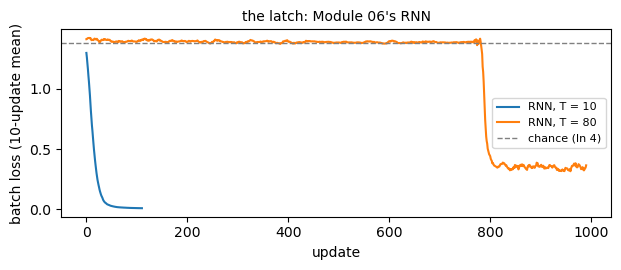

In [2]:
S = canon.latch_batch(np.random.default_rng(0), 24, 1)[:, 0]
print('one latch sequence, T = 24:  ', SYM[S[0]], ''.join(SYM[s] for s in S[1:]), ' -> answer', SYM[S[0]])

t0 = time.time()
rnn_runs = {T: canon.train_latch(T=T, kind='rnn', steps=1000, stop_after=50) for T in (10, 80)}
for T, r in rnn_runs.items():
    print(f"RNN, lag T = {T:2d}: test accuracy {r['acc'][T]:.3f} (chance 0.25), "
          f"{'solved at update ' + str(r['solved_at']) if r['solved_at'] else 'never solved'} "
          f"({len(r['loss'])} updates)")
print(f'({time.time() - t0:.0f}s)')

fig, ax = plt.subplots(figsize=(6.4, 2.8))
for T, r in rnn_runs.items():
    ax.plot(np.convolve(r['loss'], np.ones(10) / 10, mode='valid'), label=f'RNN, T = {T}')
ax.axhline(np.log(4), color='gray', ls='--', lw=1, label='chance (ln 4)')
ax.set_xlabel('update'); ax.set_ylabel('batch loss (10-update mean)'); ax.legend(fontsize=8)
ax.set_title('the latch: Module 06\'s RNN', fontsize=10); plt.tight_layout(); plt.show()

Ten steps of distractors are no obstacle; eighty are a wall. The forward pass is not the problem
— the state can carry a symbol that far, as the next section shows — the problem is learning to,
with a lesson that must travel 79 steps back through Module 06's power of a matrix.

## 2. A cell that adds

Hochreiter and Schmidhuber's long short-term memory gives the network a second state, the **cell**
$c$, that is not rewritten at every step but *added to*, under three **gates** — sigmoids between
0 and 1, computed from the input and the previous hidden state like any layer:

$$
z^{\langle t\rangle} = x^{\langle t\rangle} W_x + h^{\langle t-1\rangle} W_h + b, \qquad
i = \sigma(z_i),\; f = \sigma(z_f),\; o = \sigma(z_o),\; g = \tanh(z_g),
$$
$$
c^{\langle t\rangle} = f \odot c^{\langle t-1\rangle} + i \odot g, \qquad h^{\langle t\rangle} = o \odot \tanh\big(c^{\langle t\rangle}\big).
$$

The **input gate** $i$ decides how much of the candidate $g$ to write, the **forget gate** $f$ how
much of the old cell to keep, the **output gate** $o$ how much of the cell to show. (The 1997 cell
had no forget gate — $f = 1$, always; Gers, Schmidhuber and Cummins added it in 2000.) With $i = 0$
and $f = 1$ the cell is *unchanged*, whatever arrives. A recurrent unit cannot do that: it holds a
value only as an attractor of $\tanh(w h + \ldots)$, and attractors are few and coarse.

Below, the same four values are written at step 0 into a single LSTM cell (hand-set weights: the
input gate opens only for signals, the forget gate stays open) and into a single RNN unit, then 200
distractors go by.

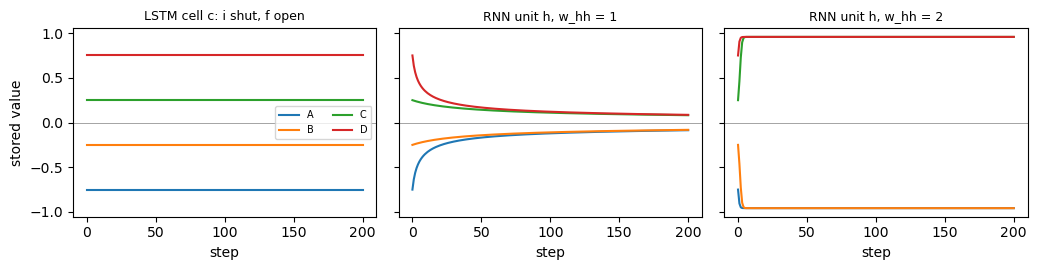

LSTM cell after 200 distractors: [-0.75 -0.25  0.25  0.75] (written: [-0.75 -0.25  0.25  0.75] )


In [3]:
VALS = np.array([-0.75, -0.25, 0.25, 0.75])            # what each signal A B C D writes
Sd = np.full((201, 4), canon.NS); Sd[0] = np.arange(4)  # step 0: A, B, C, D; then 200 distractors 'w'
Xd = canon.one_hot(Sd)

cell = ng.LSTM(canon.V, 1)                              # one cell, hand-set weights
n = 1
cell.Wx[:4, 0] = 40.0                                   # input gate: wide open for a signal...
cell.Wx[:4, 2] = np.arctanh(VALS)                       # ...which writes its value as the candidate g
cell.gate_bias(i=-20.0, f=20.0, o=20.0)                 # shut to everything else, never forget, always show
cell.forward(Xd)

fig, axs = plt.subplots(1, 3, figsize=(10.5, 2.8), sharey=True)
axs[0].plot(cell.C[:, :, 0]); axs[0].set_title('LSTM cell c: i shut, f open', fontsize=9)
for ax, w in zip(axs[1:], (1.0, 2.0)):
    unit = ng.RNN(canon.V, 1)
    unit.Wxh[:4, 0] = np.arctanh(VALS); unit.Whh[0, 0] = w   # write the same values, then recur
    ax.plot(unit.forward(Xd)[:, :, 0]); ax.set_title(f'RNN unit h, w_hh = {w:g}', fontsize=9)
for ax in axs:
    ax.set_xlabel('step'); ax.axhline(0, color='gray', lw=0.5)
axs[0].set_ylabel('stored value'); axs[0].legend(list('ABCD'), fontsize=7, ncol=2)
plt.tight_layout(); plt.show()
print('LSTM cell after 200 distractors:', np.round(cell.C[-1, :, 0], 6), '(written:', VALS, ')')

The cell holds all four values flat. The RNN unit with $w_{hh} = 1$ lets every value decay toward
zero ($\tanh(h) < h$); with $w_{hh} = 2$ it has two attractors, near $\pm 0.96$, and A and B fall into
one while C and D fall into the other — a robust memory of *one bit*, not two. That is Bengio,
Simard and Frasconi's dilemma in a picture: a recurrent net stores information robustly only by
contracting onto attractors, and contraction is what makes its gradient vanish. It is also why the
RNN runs below so often stop at 50% or 75%: two or three distinguishable states, not four.

The library's layer runs whole sequences at once; one step written out by hand is the same:

In [4]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def lstm_step(x, h_prev, c_prev, Wx, Wh, b):
    n = Wh.shape[0]
    z = x @ Wx + h_prev @ Wh + b                        # all four pre-activations at once
    i, f, g, o = sigmoid(z[:, :n]), sigmoid(z[:, n:2*n]), np.tanh(z[:, 2*n:3*n]), sigmoid(z[:, 3*n:])
    c = f * c_prev + i * g                              # keep some, write some
    return o * np.tanh(c), c                            # show some

rng = np.random.default_rng(0)
lay = ng.LSTM(5, 3)
for p in lay.params():
    p[...] = rng.standard_normal(p.shape) * 0.5
Xs = rng.standard_normal((6, 2, 5))
h, c = np.zeros((2, 3)), np.zeros((2, 3))
for t in range(6):
    h, c = lstm_step(Xs[t], h, c, lay.Wx, lay.Wh, lay.b)
H = lay.forward(Xs)
print(f'by hand vs nanograd.LSTM: h rel_error {rel_error(h, H[-1]):.1e}, c rel_error {rel_error(c, lay.C[-1]):.1e}')
assert rel_error(h, H[-1]) < 1e-12 and rel_error(c, lay.C[-1]) < 1e-12
n_rnn = 16 * 16 + 8 * 16 + 16
n_lstm = 4 * (16 * 16 + 8 * 16 + 16)
print(f'parameters at 16 units, 8 inputs: RNN {n_rnn}, LSTM {n_lstm} (four gates\' worth)')

by hand vs nanograd.LSTM: h rel_error 6.5e-15, c rel_error 6.5e-15
parameters at 16 units, 8 inputs: RNN 400, LSTM 1600 (four gates' worth)


## 3. Backpropagation through the cell

Walking backwards, an LSTM step receives **two** gradients from the future — through $h^{\langle t\rangle}$
(which the next step's gates read) and through $c^{\langle t\rangle}$ (which the next step's cell keeps):

$$
\frac{\partial L}{\partial h^{\langle t\rangle}} = dH^{\langle t\rangle} + \frac{\partial L}{\partial z^{\langle t+1\rangle}} W_h^{\top}, \qquad
\frac{\partial L}{\partial c^{\langle t\rangle}} = \frac{\partial L}{\partial c^{\langle t+1\rangle}} \odot f^{\langle t+1\rangle} + \frac{\partial L}{\partial h^{\langle t\rangle}} \odot o \odot \big(1 - \tanh^2 c^{\langle t\rangle}\big).
$$

Then the product rule gives each gate's share, and the shared weights sum their shares over every
step, as in Module 06:

$$
dz_i = dc\, g\, i(1-i), \quad dz_f = dc\, c^{\langle t-1\rangle} f(1-f), \quad dz_g = dc\, i\,(1-g^2), \quad dz_o = dh \tanh(c)\, o(1-o).
$$

The second equation is the whole point. Along the cell, one step back multiplies the gradient by
$f$ — **no weight matrix, no squashing slope**, just a number between 0 and 1 that the network sets
for itself. Hochreiter and Schmidhuber called the path the **constant error carousel**: with $f = 1$
the error rides it back any distance unchanged. Written out, then checked against finite
differences and the library:

In [5]:
def lstm_bptt(X, h0, c0, Wx, Wh, b, dH):
    """Forward, then backpropagation through time along both paths. Returns
    (dX, dWx, dWh, db, dC)."""
    T, m, _ = X.shape
    n = Wh.shape[0]
    hs, cs, gs = [h0], [c0], []
    for t in range(T):                                  # forward, keeping what backward needs
        z = X[t] @ Wx + hs[-1] @ Wh + b
        gt = np.concatenate([sigmoid(z[:, :2*n]), np.tanh(z[:, 2*n:3*n]), sigmoid(z[:, 3*n:])], axis=1)
        cs.append(gt[:, n:2*n] * cs[-1] + gt[:, :n] * gt[:, 2*n:3*n])
        hs.append(gt[:, 3*n:] * np.tanh(cs[-1])); gs.append(gt)
    dX, dWx, dWh, db = np.zeros_like(X), np.zeros_like(Wx), np.zeros_like(Wh), np.zeros_like(b)
    dC = np.zeros((T, m, n))
    dh_next, dc_next = np.zeros((m, n)), np.zeros((m, n))
    for t in range(T - 1, -1, -1):
        i, f, g, o = gs[t][:, :n], gs[t][:, n:2*n], gs[t][:, 2*n:3*n], gs[t][:, 3*n:]
        tc = np.tanh(cs[t + 1])
        dh = dH[t] + dh_next                            # from the output, and from the gates of t+1
        dc = dc_next + dh * o * (1 - tc**2)             # along the carousel, and via h<t>
        dz = np.concatenate([dc * g * i * (1 - i), dc * cs[t] * f * (1 - f),
                             dc * i * (1 - g**2), dh * tc * o * (1 - o)], axis=1)
        dWx += X[t].T @ dz; dWh += hs[t].T @ dz; db += dz.sum(0)   # every step's share
        dX[t] = dz @ Wx.T
        dh_next, dc_next = dz @ Wh.T, dc * f            # one step further back, on both paths
        dC[t] = dc
    return dX, dWx, dWh, db, dC

rng = np.random.default_rng(1)
lay = ng.LSTM(4, 5)
for p in lay.params():
    p[...] = rng.standard_normal(p.shape) * 0.6
X, dH = rng.standard_normal((7, 3, 4)), rng.standard_normal((7, 3, 5))
h0, c0 = np.zeros((3, 5)), np.zeros((3, 5))
dX, dWx, dWh, db, dC = lstm_bptt(X, h0, c0, lay.Wx, lay.Wh, lay.b, dH)
f = lambda _: lay.forward(X)
for name, mine, arr in (('dX', dX, X), ('dWx', dWx, lay.Wx), ('dWh', dWh, lay.Wh), ('db', db, lay.b)):
    err = rel_error(mine, eval_numerical_gradient_array(f, arr, dH))
    print(f'{name:4s} by hand vs finite differences: rel_error = {err:.1e}'); assert err < 1e-6
lay.forward(X); lay.backward(dH)
assert max(rel_error(a, b_) for a, b_ in zip((dWx, dWh, db, dC), (lay.dWx, lay.dWh, lay.db, lay.dC))) < 1e-12
print('...and identical to nanograd.LSTM.backward')

# Along the carousel alone (the 1997 gradient: the h path cut at every step), with an error only
# at the last step, the cell's gradient is exactly the last one times a product of forget gates.
dH1 = np.zeros_like(dH); dH1[-1] = dH[-1]
lay.forward(X); lay.backward(dH1, cell_only=True)
Fg = lay.G[:, :, 5:10]
pred = np.stack([lay.dC[-1] * np.prod(Fg[t + 1:], axis=0) for t in range(7)])
print(f'cell-only dc<t> vs dc<T-1> * prod f: max|diff| = {np.abs(pred - lay.dC).max():.1e}')
assert np.abs(pred - lay.dC).max() < 1e-12

dX   by hand vs finite differences: rel_error = 5.3e-10
dWx  by hand vs finite differences: rel_error = 1.7e-09


dWh  by hand vs finite differences: rel_error = 7.7e-09
db   by hand vs finite differences: rel_error = 3.2e-10
...and identical to nanograd.LSTM.backward
cell-only dc<t> vs dc<T-1> * prod f: max|diff| = 2.8e-17


## 4. Four networks, one latch

Now the latch at $T = 80$, with four networks trained on the same batches — the four twins of
`c/lstm.c`, here on nanograd's fast path:

| twin | network | gate biases | gradient |
|------|---------|-------------|----------|
| `rnn` | Module 06's RNN | — | full BPTT |
| `forget1` | LSTM | input 0, forget **1** (the textbook) | full BPTT |
| `lstm` | LSTM, the same weights | input **−5**, forget **+5** | full BPTT |
| `carousel` | LSTM, the same weights | input −5, forget +5 | **cell only** (1997) |

A forget bias of 1 is the customary choice (Jozefowicz, Zaremba and Sutskever 2015; Keras's
default): $\sigma(1) = 0.73$, a cell that starts out keeping most of itself. The third twin starts its
cells *open to the past* ($\sigma(5) = 0.993$) and *shut to new input* ($\sigma(-5) = 0.007$) — why,
§7 measures. The sweeps below run in a pool of worker processes (`canon.sweep`), one training run
per core.

(13s, in parallel)
rnn       test accuracy at T = 80: 0.285, at T = 320: 0.254; solved at None; clipped 0 of 600 updates; largest |g| 0.93
forget1   test accuracy at T = 80: 0.270, at T = 320: 0.254; solved at None; clipped 0 of 600 updates; largest |g| 0.49
lstm      test accuracy at T = 80: 1.000, at T = 320: 1.000; solved at 143; clipped 27 of 600 updates; largest |g| 46.32
carousel  test accuracy at T = 80: 1.000, at T = 320: 0.996; solved at 127; clipped 7 of 600 updates; largest |g| 1.52


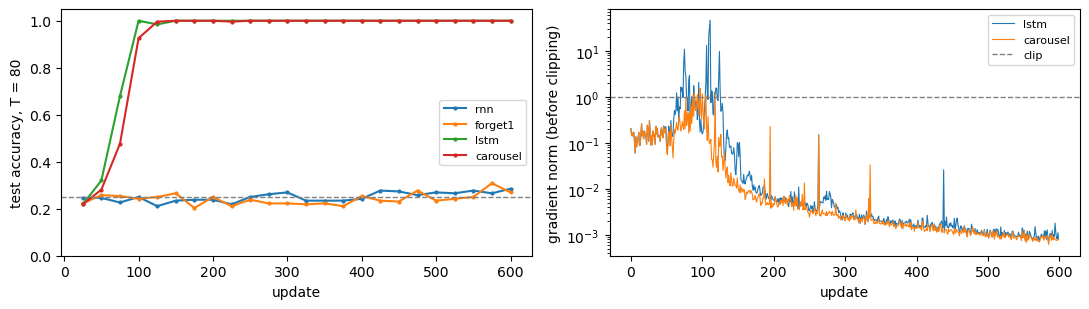

In [6]:
TWIN_CFG = {
    'rnn':      dict(kind='rnn'),
    'forget1':  dict(kind='lstm', bias=canon.TEXTBOOK_BIAS),
    'lstm':     dict(kind='lstm', bias=canon.OPEN_BIAS),
    'carousel': dict(kind='lstm', bias=canon.OPEN_BIAS, cell_only=True),
}
t0 = time.time()
twins = dict(zip(TWIN_CFG, canon.sweep([dict(T=80, steps=600, record_every=25, **c) for c in TWIN_CFG.values()])))
print(f'({time.time() - t0:.0f}s, in parallel)')
for name, r in twins.items():
    print(f"{name:9s} test accuracy at T = 80: {r['acc'][80]:.3f}, at T = 320: {r['acc'][320]:.3f}; "
          f"solved at {r['solved_at']}; clipped {r['n_clip']} of 600 updates; largest |g| {max(r['norm']):.2f}")

fig, axs = plt.subplots(1, 2, figsize=(11, 3.2))
for name, r in twins.items():
    u, a = zip(*r['curve'])
    axs[0].plot(u, a, label=name, marker='o', ms=2)
axs[0].axhline(0.25, color='gray', ls='--', lw=1); axs[0].set_ylim(0, 1.05)
axs[0].set_xlabel('update'); axs[0].set_ylabel('test accuracy, T = 80'); axs[0].legend(fontsize=8)
for name in ('lstm', 'carousel'):
    axs[1].semilogy(twins[name]['norm'], label=name, lw=0.8)
axs[1].axhline(canon.CLIP, color='gray', ls='--', lw=1, label='clip')
axs[1].set_xlabel('update'); axs[1].set_ylabel('gradient norm (before clipping)'); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

The RNN and the textbook LSTM stay at chance. The open LSTM is perfect within about 150 updates —
and so is its carousel twin, whose gradient never travels back through $h$ at all: the error that
teaches step 0 to keep its symbol rides the cell the whole way. The right panel previews §8: the
full gradient spikes when the network finds the solution; the carousel's does not.

## 5. How long a lag?

The same comparison across lags, three seeds each, a budget of 1,000 updates (a run stops early
once it has solved the task):

36 runs in 39s
   lag T                10                20                40                80               160               320
         RNN    1.00 1.00 1.00    1.00 0.49 1.00    0.48 0.73 0.44    0.78 0.26 0.48    1.00 0.25 0.26    0.24 0.43 0.79
 LSTM (open)    1.00 1.00 1.00    1.00 1.00 1.00    1.00 1.00 1.00    1.00 1.00 1.00    1.00 1.00 1.00    1.00 1.00 1.00
LSTM solved at update: {10: [103, 104, 103], 20: [117, 103, 101], 40: [120, 105, 104], 80: [143, 119, 117], 160: [129, 151, 133], 320: [205, 292, 363]}


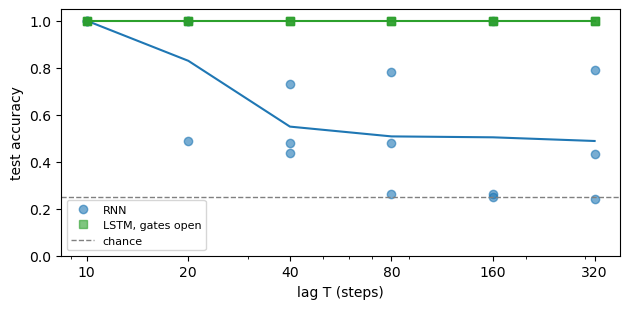

In [7]:
LAGS = (10, 20, 40, 80, 160, 320)
cfgs = [dict(T=T, kind=k, seed=s, steps=1000, stop_after=50) for k in ('rnn', 'lstm') for T in LAGS for s in range(3)]
t0 = time.time()
lag_runs = canon.sweep(cfgs)
print(f'{len(cfgs)} runs in {time.time() - t0:.0f}s')
lag_acc = {k: np.array([[r['acc'][c['T']] for c, r in zip(cfgs, lag_runs) if c['kind'] == k and c['T'] == T]
                        for T in LAGS]) for k in ('rnn', 'lstm')}
lag_solved = {k: [[r['solved_at'] for c, r in zip(cfgs, lag_runs) if c['kind'] == k and c['T'] == T]
                  for T in LAGS] for k in ('rnn', 'lstm')}
print(f"{'lag T':>8s}" + ''.join(f'{T:>18d}' for T in LAGS))
for k, label in (('rnn', 'RNN'), ('lstm', 'LSTM (open)')):
    print(f'{label:>12s}' + ''.join(f"{' '.join(f'{a:.2f}' for a in row):>18s}" for row in lag_acc[k]))
print('LSTM solved at update:', {T: s for T, s in zip(LAGS, lag_solved['lstm'])})

fig, ax = plt.subplots(figsize=(6.4, 3.2))
for k, label, mk in (('rnn', 'RNN', 'o'), ('lstm', 'LSTM, gates open', 's')):
    for s in range(3):
        ax.semilogx(LAGS, lag_acc[k][:, s], mk, color='C0' if k == 'rnn' else 'C2', alpha=0.6,
                    label=label if s == 0 else None)
    ax.semilogx(LAGS, lag_acc[k].mean(1), '-', color='C0' if k == 'rnn' else 'C2')
ax.axhline(0.25, color='gray', ls='--', lw=1, label='chance')
ax.set_xticks(LAGS, [str(T) for T in LAGS]); ax.set_xlabel('lag T (steps)'); ax.set_ylabel('test accuracy')
ax.set_ylim(0, 1.05); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

The RNN holds the signal across 10 steps every time and across 20 two times in three; from 40 on,
one run in twelve reaches 100% (at $T = 160$). In the rest it often gets partway — 44% to 79% —
telling two or three of the four signals apart: two or three attractors, as in §2's picture. The open LSTM solves all eighteen runs, at every lag up to 320, in
100 to 360 updates.

## 6. Why: the gradient through time

Send a unit gradient into the last hidden state of 80-step sequences and measure how much reaches
the *input* $k$ steps back, $\|\partial L/\partial x^{\langle T-1-k\rangle}\|$, relative to the last
step's — a measure that means the same thing for both architectures — and, for the LSTMs, how much
rides the cell, $\|\partial L/\partial c^{\langle T-1-k\rangle}\|$. At initialization:

                            k = 1     k = 10     k = 40     k = 79
RNN (Xavier)              7.9e-01    1.5e-01    1.2e-03    3.4e-06   input
LSTM, forget bias 1       6.8e-01    1.9e-01    6.4e-03    8.6e-05   input
                          7.5e-01    2.1e-01    8.3e-03    1.1e-04   cell
LSTM, gates open          2.0e-01    1.9e-01    1.5e-01    1.1e-01   input
                          9.9e-01    9.3e-01    7.5e-01    5.9e-01   cell
sigma(5)^79 = 0.59: the open cell's product of forget gates


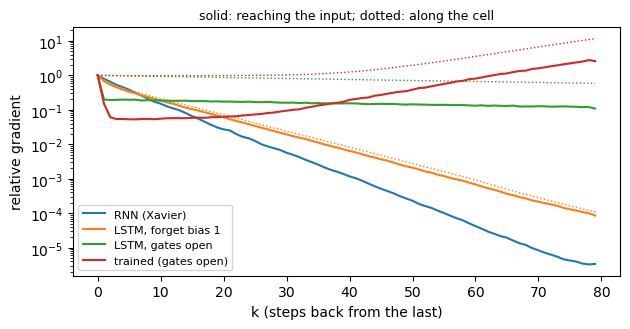

In [8]:
KS = (1, 10, 40, 79)
profiles = {}
for name, kind, bias in (('RNN (Xavier)', 'rnn', None), ('LSTM, forget bias 1', 'lstm', canon.TEXTBOOK_BIAS),
                         ('LSTM, gates open', 'lstm', canon.OPEN_BIAS)):
    lay, _ = canon.build_latch_net(kind, Rng(canon.TOY_SEED), bias=bias)
    profiles[name] = canon.grad_through_time(lay, T=80)
print(f"{'':22s}" + ''.join(f'{f"k = {k}":>11s}' for k in KS))
for name, g in profiles.items():
    print(f'{name:22s}' + ''.join(f"{g['x'][k]:11.1e}" for k in KS) + '   input')
    if 'c' in g:
        print(f"{'':22s}" + ''.join(f"{g['c'][k]:11.1e}" for k in KS) + '   cell')
print(f'sigma(5)^79 = {(1 / (1 + math.exp(-5))) ** 79:.2f}: the open cell\'s product of forget gates')

trained = canon.train_latch(T=80, kind='lstm', steps=1000, stop_after=50)
profiles['trained (gates open)'] = canon.grad_through_time(trained['layer'], T=80)

fig, ax = plt.subplots(figsize=(6.4, 3.4))
for (name, g), col in zip(profiles.items(), ('C0', 'C1', 'C2', 'C3')):
    ax.semilogy(g['x'], color=col, label=name)
    if 'c' in g:
        ax.semilogy(g['c'], color=col, ls=':', lw=1)
ax.set_xlabel('k (steps back from the last)'); ax.set_ylabel('relative gradient')
ax.set_title('solid: reaching the input; dotted: along the cell', fontsize=9); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

At initialization the RNN's gradient falls about tenfold every fifteen steps and is down to a few
millionths at the signal. The textbook LSTM is barely better: with $f \approx 0.73$ its carousel
leaks a quarter of the gradient every step, and $0.73^{79}$ is $10^{-11}$ (the cell profile decays
more slowly than that only because the $h$ path keeps feeding it). The open cell's product of
forget gates is $\sigma(5)^{79} \approx 0.59$, and about a tenth of the last step's gradient reaches
the signal 79 steps back. That is the difference between §4's chance and §4's perfect score — the
forward pass, remember, could carry the symbol in all three. (The trained network's gradient even
*grows* on the way back, to several times the last step's at the signal: §9 shows why.)

## 7. Two biases, two jobs

At the start of training the forget gate is about $\sigma(b_f)$ everywhere, so the cell keeps
$\sigma(b_f)^k$ of what it held $k$ steps ago — and so does the gradient along it. Its memory lasts
about $1/(1-\sigma(b_f))$ steps:

In [9]:
for b in (0, 1, 3, 5, 7):
    s = 1 / (1 + math.exp(-b))
    print(f'forget bias {b}: f = {s:.4f}, memory ~ {1 / (1 - s):7.1f} steps, cell gradient 79 steps back ~ {s ** 79:.1e}')

forget bias 0: f = 0.5000, memory ~     2.0 steps, cell gradient 79 steps back ~ 1.7e-24
forget bias 1: f = 0.7311, memory ~     3.7 steps, cell gradient 79 steps back ~ 1.8e-11
forget bias 3: f = 0.9526, memory ~    21.1 steps, cell gradient 79 steps back ~ 2.2e-02
forget bias 5: f = 0.9933, memory ~   149.4 steps, cell gradient 79 steps back ~ 5.9e-01
forget bias 7: f = 0.9991, memory ~  1097.6 steps, cell gradient 79 steps back ~ 9.3e-01


The forget bias is half the story. A cell that never forgets also never stops *collecting*: at
initialization the input gate is $\sigma(b_i)$ for every distractor, and each one writes $i\,g$ into
the cell. With $b_i = 0$ that is a random walk — after a few hundred steps the cell holds mostly the
sum of the distractors, the signal's share is a fraction of one unit inside it, and $\tanh$ has
saturated, so the output barely moves when the cell does. Hochreiter and Schmidhuber called it
**internal state drift** ("the $h'(s_j)$ will then adopt very small values, and the gradient will
vanish"), and their remedy (§4.8 of the 1997 paper) was "initially to bias the input gate $in_j$
toward zero". Measured at initialization, forget bias 5, $T = 320$:

input bias +0: mean |c| at steps 1, 80, 320 = 0.146, 5.79, 14.76; mean tanh slope 1 - tanh(c)^2 at the end 0.11


input bias -5: mean |c| at steps 1, 80, 320 = 0.002, 0.05, 0.10; mean tanh slope 1 - tanh(c)^2 at the end 0.98


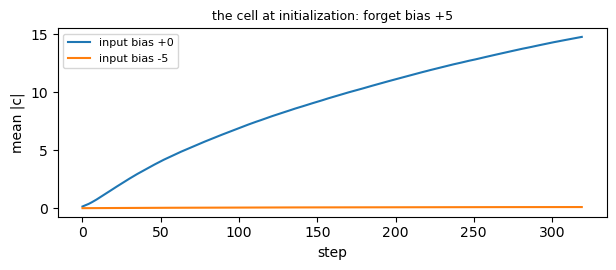

In [10]:
Sl = canon.latch_batch(np.random.default_rng(3), 320, 256)
fig, ax = plt.subplots(figsize=(6.4, 2.8))
for bi in (0.0, -5.0):
    lay, _ = canon.build_latch_net('lstm', Rng(canon.TOY_SEED), bias={'i': bi, 'f': 5.0})
    lay.forward(canon.one_hot(Sl))
    cabs = np.abs(lay.C).mean(axis=(1, 2))
    slope = (1 - np.tanh(lay.C[-1]) ** 2).mean()
    print(f'input bias {bi:+.0f}: mean |c| at steps 1, 80, 320 = {cabs[0]:.3f}, {cabs[79]:.2f}, {cabs[-1]:.2f}; '
          f'mean tanh slope 1 - tanh(c)^2 at the end {slope:.2f}')
    ax.plot(cabs, label=f'input bias {bi:+.0f}')
ax.set_xlabel('step'); ax.set_ylabel('mean |c|'); ax.legend(fontsize=8)
ax.set_title('the cell at initialization: forget bias +5', fontsize=9); plt.tight_layout(); plt.show()

The two biases together, on the latch — first one knob, $b_f = b$ and $b_i = -b$ (the pairing
Tallec and Ollivier's 2018 "chrono" initialization uses), then the input bias alone at $b_f = 5$ and
$T = 320$; two seeds each, a budget of 1,000 updates:

In [11]:
BS, BT = (0, 1, 2, 3, 5, 7), (20, 80, 320)
BI = (0, -1, -2, -3, -5)
cfg_a = [dict(T=T, kind='lstm', bias={'i': -float(b), 'f': float(b)}, seed=s, steps=1000, stop_after=50)
         for b in BS for T in BT for s in range(2)]
cfg_b = [dict(T=320, kind='lstm', bias={'i': float(bi), 'f': 5.0}, seed=s, steps=1000, stop_after=50)
         for bi in BI for s in range(2)]
t0 = time.time()
res = canon.sweep(cfg_a + cfg_b)
print(f'{len(res)} runs in {time.time() - t0:.0f}s\n')
res_a, res_b = res[:len(cfg_a)], res[len(cfg_a):]
bias_acc = np.array([r['acc'][c['T']] for c, r in zip(cfg_a, res_a)]).reshape(len(BS), len(BT), 2)
print(f"{'b_f = b, b_i = -b':>18s}" + ''.join(f'{f"T = {T}":>14s}' for T in BT) + '   memory at init')
for b, row in zip(BS, bias_acc):
    mem = 1 / (1 - 1 / (1 + math.exp(-b)))
    print(f'{"b = " + str(b):>18s}' + ''.join(f"{' '.join(f'{a:.2f}' for a in cell):>14s}" for cell in row)
          + f'   {mem:8.1f} steps')
input_acc = np.array([r['acc'][320] for r in res_b]).reshape(len(BI), 2)
print(f"\n{'b_f = 5, T = 320':>18s}" + ''.join(f'{f"b_i = {bi}":>12s}' for bi in BI))
print(f"{'':>18s}" + ''.join(f"{' '.join(f'{a:.2f}' for a in cell):>12s}" for cell in input_acc))

46 runs in 100s

 b_f = b, b_i = -b        T = 20        T = 80       T = 320   memory at init
             b = 0     0.21 0.27     0.30 0.27     0.24 0.24        2.0 steps
             b = 1     1.00 1.00     0.29 0.27     0.28 0.24        3.7 steps
             b = 2     1.00 1.00     0.25 0.25     0.27 0.24        8.4 steps
             b = 3     1.00 1.00     1.00 1.00     0.24 0.24       21.1 steps
             b = 5     1.00 1.00     1.00 1.00     1.00 1.00      149.4 steps
             b = 7     1.00 1.00     1.00 1.00     1.00 1.00     1097.6 steps

  b_f = 5, T = 320     b_i = 0    b_i = -1    b_i = -2    b_i = -3    b_i = -5
                     0.77 0.24   0.24 0.24   0.44 0.24   1.00 1.00   1.00 1.00


Each row learns the lags its memory can bridge — a few times its initial lifetime — and fails beyond
them; and at $T = 320$ even a forget gate held open fails unless the input gate starts nearly shut
(a bias of −3 or below, $\sigma(-3) = 0.047$). Neither
bias is a fix for the RNN's problem by itself: the forget bias makes the gradient *able* to travel,
the input bias keeps what it travels through from turning to noise.

## 8. The carousel alone — and why it cannot explode

Hochreiter and Schmidhuber did not backpropagate through the whole network. Their 1997 algorithm
truncated the gradient wherever it tried to leave a memory cell or a gate: error flowed back in time
only along the cells' self-loops. That is `cell_only=True` — and §4 showed it learns the latch as
well as the full gradient. Eight seeds, both ways, 300 updates each at $T = 80$:

In [12]:
cfgs = [dict(T=80, kind='lstm', cell_only=co, seed=s, steps=300) for co in (False, True) for s in range(8)]
car = canon.sweep(cfgs)
print(f"{'':10s}{'solved':>8s}{'mean update':>13s}{'acc at 4T':>12s}{'clipped':>10s}{'max |g|':>10s}")
for co, label in ((False, 'full BPTT'), (True, 'cell only')):
    rs = [r for c, r in zip(cfgs, car) if c['cell_only'] == co]
    sol = [r['solved_at'] for r in rs if r['solved_at']]
    print(f"{label:10s}{len(sol):>6d}/8{np.mean(sol):>13.0f}{np.mean([r['acc'][320] for r in rs]):>12.3f}"
          f"{np.mean([r['n_clip'] for r in rs]):>10.1f}{max(max(r['norm']) for r in rs):>10.2f}")
    print(f"{'':10s}  per seed: clipped {[r['n_clip'] for r in rs]}, acc at 4T {[round(r['acc'][320], 2) for r in rs]}")

            solved  mean update   acc at 4T   clipped   max |g|
full BPTT      8/8          119       0.971      14.1     46.32
            per seed: clipped [27, 12, 11, 16, 12, 13, 11, 11], acc at 4T [1.0, 1.0, 0.77, 1.0, 1.0, 1.0, 1.0, 1.0]
cell only      8/8          119       1.000       1.1      1.52
            per seed: clipped [7, 0, 0, 2, 0, 0, 0, 0], acc at 4T [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


The cell-only gradient solves every seed, holds on sequences four times longer, and almost never
needs clipping; the full gradient solves every seed too, but spikes past the clipping threshold a
dozen or more times per run. The reason is the carousel's equation. Along the cell the gradient is
multiplied, step after step, by forget gates between 0 and 1 — **it can fade, but it cannot
explode**. Every spike comes from the $h$ path, $dz^{\langle t+1\rangle} W_h^{\top}$, which is a
recurrent network's product of matrices again. The 1997 truncation removed exactly the part of the
gradient that can blow up, and kept the part that carries the memory; it was also far cheaper,
because it needs no stored history. (Graves and Schmidhuber returned to the full gradient in 2005,
and every framework computes it today — with clipping.)

## 9. Inside the trained latch

What did the open LSTM actually learn? Run 64 test sequences through it, and follow the cell that
best separates the four signals, and the gates:

cell 13: |c| at step 0 = 0.027, at step 79 = 1.75
input gate: at the signal 0.028, at distractors 0.081; forget gate, mean over steps 1-79: 0.984 (min 0.237)


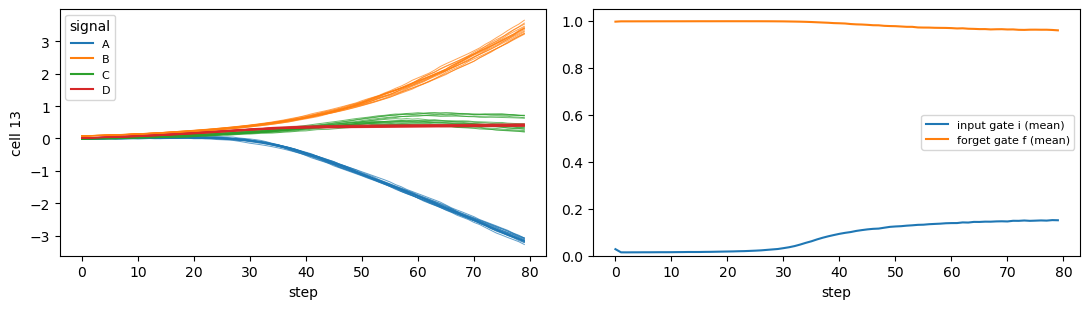

In [13]:
trained = canon.train_latch(T=80, kind='lstm', steps=1000, stop_after=50, seed=0)
lay = trained['layer']
St = canon.latch_batch(np.random.default_rng(7), 80, 64)
lay.forward(canon.one_hot(St))
n = lay.n_h
C, I, Fg = lay.C, lay.G[:, :, :n], lay.G[:, :, n:2*n]
# the cell whose final value best separates the signals (between-signal share of its variance)
share = np.array([np.var([C[-1, St[0] == k, j].mean() for k in range(4)]) / (C[-1, :, j].var() + 1e-12)
                  for j in range(n)])
j = int(share.argmax())
print(f'cell {j}: |c| at step 0 = {np.abs(C[0, :, j]).mean():.3f}, at step 79 = {np.abs(C[-1, :, j]).mean():.2f}')
print(f'input gate: at the signal {I[0].mean():.3f}, at distractors {I[1:].mean():.3f}; '
      f'forget gate, mean over steps 1-79: {Fg[1:].mean():.3f} (min {Fg[1:].min():.3f})')

fig, axs = plt.subplots(1, 2, figsize=(11, 3.2))
for k in range(4):
    axs[0].plot(C[:, St[0] == k, j], color=f'C{k}', lw=0.7, alpha=0.7)
    axs[0].plot([], [], color=f'C{k}', label=canon.SIGNALS[k])
axs[0].set_xlabel('step'); axs[0].set_ylabel(f'cell {j}'); axs[0].legend(fontsize=8, title='signal')
axs[1].plot(I.mean(axis=(1, 2)), label='input gate i (mean)')
axs[1].plot(Fg.mean(axis=(1, 2)), label='forget gate f (mean)')
axs[1].set_ylim(0, 1.05); axs[1].set_xlabel('step'); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

Not the textbook latch. The input gate never opens at the signal — it is *lower* there than at the
distractors — so step 0 leaves only a faint mark in the cell, a few hundredths. The forget gate stays
near 1, so the mark survives; and after twenty-odd steps the input gate opens a little for
everything, and through the $h$ path each step writes a little more *in the direction of what is
already stored*. This one cell sends A and B apart in opposite directions and leaves C and D near
zero (other cells split those two); by step 79 the mark has grown sixtyfold, to where the read-out
can use it. A memory that is kept, then amplified — the reason the trained network's gradient in §6
grows on the way back. Gradient descent finds whatever works.

## 10. Verify against the canonical `lstm.py` and the C mirror

`ToyLatch` trains the four twins with every sum in `lib/c/nanograd`'s loop order, from the same LCG
streams as `c/lstm.c`, with the C library's own `exp` and `tanh`. `tests/test_agreement.py`
compiles the C and asserts every fingerprint matches.

In [14]:
t0 = time.time()
tests = canon.test_sets()
fp = {tw: dict(canon.run_toy(tw, tests=tests)) for tw in canon.TWINS}
print(f"{'':11s}" + ''.join(f'{tw:>22s}' for tw in canon.TWINS) + f'   ({time.time() - t0:.0f}s of C-order NumPy)')
for key in fp['rnn']:
    print(f'{key:11s}' + ''.join(f'{fp[tw][key]:22.15g}' for tw in canon.TWINS))
assert fp['rnn']['acc'] < 0.5 and fp['forget1']['acc'] < 0.5
assert fp['lstm']['acc'] == 1.0 and fp['carousel']['acc'] == 1.0 and fp['carousel']['acc4'] == 1.0
assert fp['carousel']['n_clip'] < fp['lstm']['n_clip']
print('OK: the RNN and the textbook LSTM cannot hold the signal 80 steps; the open LSTM and its carousel '
      'twin can; c/lstm.c prints the same digits (see tests/test_agreement.py)')

                              rnn                  lstm              carousel               forget1   (91s of C-order NumPy)
loss             1.39995499378179  0.000835182534943463  0.000806942380216398      1.38202980046429
acc                          0.25                     1                     1              0.265625
acc4                         0.25              0.765625                     1              0.203125
batch_loss       1.39196121245309  0.000858044550107835  0.000813753887736706      1.38325454483772
gnorm           0.280680822027248   0.00185771077430427   0.00176984905433081    0.0933144598438757
n_clip                          4                    45                     2                     0
wsum             9.76063009591615      196.584420368104      153.371597062164     -16.1783020953455
win_00         -0.621840960287122     0.892324362308209      1.02902031368714    -0.514964274810498
wrec_00        -0.357966288271099    -0.396769265285743     -0.271572808225

## 11. Tiny Shakespeare: the same budget, the same task

Module 06's character model, with the RNN swapped for an LSTM sized to the same parameter budget:
122 cells give 99,739 parameters against the RNN's 99,137 (an LSTM cell costs four times what a
recurrent unit does, so it gets half the width). Everything else is Module 06's: 64 parallel
streams, 64-step truncated BPTT with the state carried across updates, Adam, clipping at 5,
float32, 20 epochs, the learning rate halved twice near the end. The customary forget bias of 1:
text gives an error signal at every step, so nothing has to be carried blind for hundreds of
steps.

Module 06 trained its RNN at a learning rate of $2\times10^{-3}$. An architecture compared at another
one's learning rate is not compared fairly, so both are trained at every rate in a small grid, each
cached (`canon.char_sweep` trains whatever is missing, in parallel — about half an hour of wall time
from a cold cache):

In [15]:
data = canon.load_text_data()
train_ids, val_ids, chars = data
V_CH = len(chars)
jobs = [('rnn', dict(lr=lr)) for lr in canon.LR_GRID] + [('lstm', dict(lr=lr)) for lr in canon.LR_GRID]
jobs += [('lstm', dict(n_h=256, lr=2e-3))]              # an LSTM as wide as the RNN
t0 = time.time()
bracket = canon.char_sweep(jobs)
print(f'({time.time() - t0:.0f}s; cached runs load instantly)\n')
val = {(k, kw.get('lr', canon.CHAR_LR), kw.get('n_h')): v for (k, kw), (v, _) in zip(jobs, bracket)}
print(f"{'validation loss (nats/char)':30s}" + ''.join(f'{f"lr {lr:g}":>11s}' for lr in canon.LR_GRID))
for k, label in (('rnn', 'RNN, 256 units (99,137)'), ('lstm', 'LSTM, 122 cells (99,739)')):
    print(f'{label:30s}' + ''.join(f'{val[(k, lr, None)]:11.4f}' for lr in canon.LR_GRID))
print(f"\nLSTM, 256 cells (346,433 params), at Module 06's lr 0.002: {val[('lstm', 2e-3, 256)]:.4f}")

(1s; cached runs load instantly)

validation loss (nats/char)      lr 0.002   lr 0.004   lr 0.008   lr 0.016   lr 0.032
RNN, 256 units (99,137)            1.6535     1.6439     1.7693     2.2905     3.3703
LSTM, 122 cells (99,739)           1.7239     1.6556     1.6244     1.6202     1.6669

LSTM, 256 cells (346,433 params), at Module 06's lr 0.002: 1.5816


At Module 06's learning rate the LSTM *loses*, by 0.07 nats. Each at its own best — $4\times10^{-3}$
for the RNN, $1.6\times10^{-2}$ for the LSTM, both inside the grid — the LSTM wins, 1.620 against
1.644: 0.024 nats per character at the same parameter budget. The two want very different steps:
the RNN stalls at $1.6\times10^{-2}$ (2.29) and learns nothing at $3.2\times10^{-2}$ (3.37, a unigram's
loss), where the LSTM is still within 0.05 of its best. And an LSTM as wide as the RNN — 256 cells, three and a half times the
parameters — reaches 1.582 even at the RNN's original rate.

[char] loaded checkpoint 81216b9b2e74 (20 epochs, val_loss=1.6202)
[char] loaded checkpoint 8dbbbc0e4638 (20 epochs, val_loss=1.6439)

LSTM (99,739 params, lr 0.016): 1.6202 nats/char (2.337 bits)
RNN  (99,137 params, lr 0.004): 1.6439   (Module 06, lr 0.002: 1.6535)


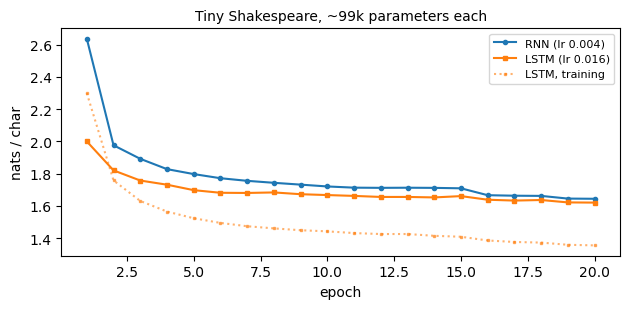

In [16]:
model, val_loss, hist = canon.run_char(data=data, cache=True, verbose=True)        # the LSTM at its best rate
rnn_model, rnn_val, rnn_hist = canon.load_rnn(data=data, verbose=True)             # the RNN at its best rate
m06_val = val[('rnn', 2e-3, None)]
n_par = sum(p.size for p in model.params())
print(f'\nLSTM ({n_par:,} params, lr {canon.CHAR_LR:g}): {val_loss:.4f} nats/char ({val_loss / math.log(2):.3f} bits)')
print(f'RNN  ({sum(p.size for p in rnn_model.params()):,} params, lr {canon.RNN_LR:g}): {rnn_val:.4f}   '
      f'(Module 06, lr 0.002: {m06_val:.4f})')
assert val_loss <= canon.CHAR_TARGET and val_loss < rnn_val

fig, ax = plt.subplots(figsize=(6.4, 3.2))
ep = np.arange(1, len(hist) + 1)
ax.plot(ep, [h['val_loss'] for h in rnn_hist], 'o-', ms=3, label=f'RNN (lr {canon.RNN_LR:g})')
ax.plot(ep, [h['val_loss'] for h in hist], 's-', ms=3, label=f'LSTM (lr {canon.CHAR_LR:g})')
ax.plot(ep, [h['train_loss'] for h in hist], 's:', ms=2, color='C1', alpha=0.6, label='LSTM, training')
ax.set_xlabel('epoch'); ax.set_ylabel('nats / char'); ax.legend(fontsize=8)
ax.set_title('Tiny Shakespeare, ~99k parameters each', fontsize=10); plt.tight_layout(); plt.show()

The LSTM is ahead at every epoch. Both fit their training text far better than the validation text
— the LSTM's training loss ends near 1.36 — which is Module 08's subject.

### What it writes

In [17]:
for e in (0, 2, len(hist) - 1):
    print(f'--- LSTM after epoch {e + 1} (temperature 0.8) ---\n{hist[e]["sample"][:300]}\n')

--- LSTM after epoch 1 (temperature 0.8) ---
ROMEO:
Thae, prown thing fold priyting and my'll of the spasce my all not what.
Whatited my prockis try would undes prat
Those heur drace on heresand;
Bure. 
JULIET:
And will they courustel on lord me wichor come, I seide it thou but be sins mares wirn stare your appill hee last ontenty stish that i

--- LSTM after epoch 3 (temperature 0.8) ---
ROMEO:
Sicch. Thou tanesh hand; atter, and my grace the spenan;
That I do your honoust thee son out
Would thence it so raplobs for her before it, but belass.

BUCKINGHAM:
There hraming, speak doth condse sumband our pardon this;
And man: he'll sivering or they hen, there he hath spronts stay,
That i

--- LSTM after epoch 20 (temperature 0.8) ---
ROMEO:
Reacher or Claudio images your hands, when he's a seried
What and eye to what, in the purpose: were he?

KING RICHARD III:
No, call the streign no sought it:
The knownest your nurse but my lambaticly,
And such a breathest best be so, and nor sleep;
They

Letter soup, then the form of a play, then mostly real words and speaker names that exist — by ear,
much like Module 06's model. A difference of 0.024 nats per character is not one you hear in a
sample; the next two measurements show where it lives.

### How far back does each model look?

Start each model from the zero state $L$ characters before a position, let it read those $L$
characters, and score its prediction of the next one; average over 4,096 positions of the
validation text. The curve flattens where extra context stops helping:

 context L      1      2      4      8     16     32     64    128    256    512   (76s)
       RNN  3.785  3.076  2.235  1.720  1.631  1.631  1.631  1.631  1.631  1.631
      LSTM  4.211  3.769  2.697  1.825  1.656  1.618  1.603  1.604  1.604  1.604


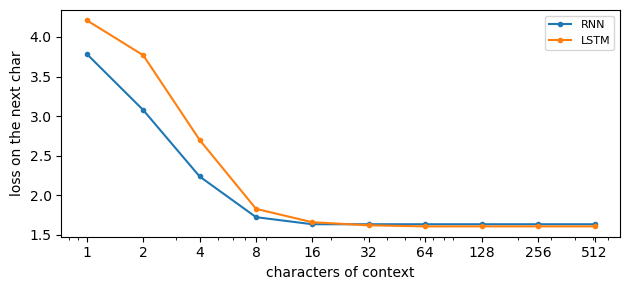

In [18]:
CTX = (1, 2, 4, 8, 16, 32, 64, 128, 256, 512)
t0 = time.time()
ctx = {'RNN': canon.context_curve(rnn_model, val_ids, CTX, n=4096),
       'LSTM': canon.context_curve(model, val_ids, CTX, n=4096)}
print(f"{'context L':>10s}" + ''.join(f'{L:>7d}' for L in CTX) + f'   ({time.time() - t0:.0f}s)')
for k, row in ctx.items():
    print(f'{k:>10s}' + ''.join(f'{x:7.3f}' for x in row))
fig, ax = plt.subplots(figsize=(6.4, 3.0))
for k, row in ctx.items():
    ax.semilogx(CTX, row, 'o-', ms=3, label=k)
ax.set_xticks(CTX, [str(L) for L in CTX]); ax.set_xlabel('characters of context')
ax.set_ylabel('loss on the next char'); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

The RNN's prediction stops improving after 16 characters: nothing it read further back changes its
guess. The LSTM's keeps improving out to 64 — 1.656 at 16, 1.618 at 32, 1.603 at 64 — and stops
there, at the length of the window it was trained on: the gradient that taught it never reached
further back than that. Those extra 48 characters are where the LSTM's advantage comes from.
(Started cold, the LSTM is worse with sixteen characters of context or fewer — its cells normally
carry values far from zero, as the next cell shows, and the zero state is one it rarely saw in
training.)

### A cell that counts

Karpathy, Johnson and Fei-Fei (2015) went looking inside character-level LSTMs and found cells
with jobs: one turned on inside quotation marks, one tracked the position in the line. Tiny
Shakespeare's lines are verse, a few dozen characters each. For every validation character, take
"characters since the last newline", and ask how well each cell — and each of the RNN's units —
tracks it:

LSTM: best cell 11, correlation +0.787; all 122 cells, linear R^2 = 0.807
RNN:  best unit 103, correlation -0.353; all 256 units, linear R^2 = 0.356
cell 11's forget gate: 0.75 at a newline, 0.93 elsewhere


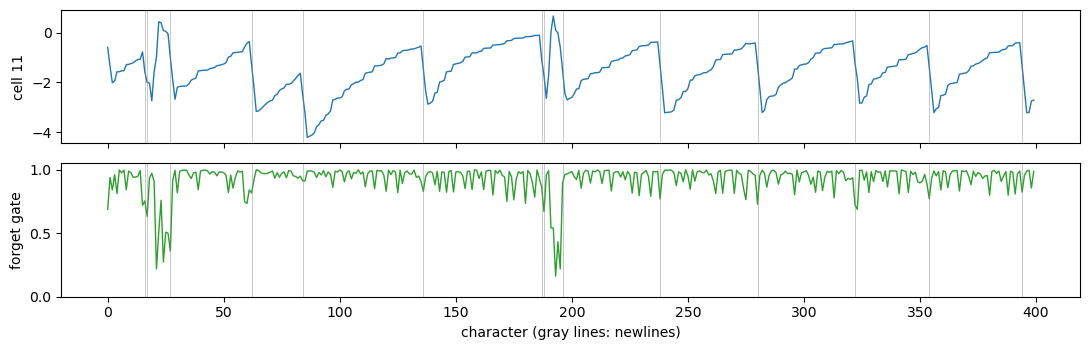

'ept his service.\n\nBAPTISTA:\nA thousand thanks, Signior Gremio.\nWelcome, good Cambio.\nBut, gentle sir, methinks you walk like a stranger:\nmay I be so bold to know the cause of your coming?\n\nTRANIO:\nPar'


In [19]:
text = ''.join(chars[i] for i in val_ids)
M_STREAMS = 32
model.nll(val_ids, m=M_STREAMS)                                        # leaves every step's cell in model.cells
Ls = (val_ids.size - 1) // M_STREAMS
cells = model.cells.reshape(-1, model.n_h).astype(np.float64)          # (32 * Ls, 122): the cell after reading each char
xs = val_ids[:M_STREAMS * Ls].reshape(M_STREAMS, Ls).T
Hr = np.empty((Ls, M_STREAMS, rnn_model.n_h), dtype=np.float32)
h = rnn_model.zero_state(M_STREAMS)
for s in range(0, Ls, 256):
    _, Hc = rnn_model.logits(xs[s:s + 256], h); h = Hc[-1]; Hr[s:s + 256] = Hc
units = Hr.transpose(1, 0, 2).reshape(-1, rnn_model.n_h).astype(np.float64)
pos = np.minimum(canon.line_position(text[:M_STREAMS * Ls]), 80).astype(float)

def track(A, y):
    """(each unit's correlation with y, R^2 of the best linear read-out of y from all units)."""
    A0, y0 = A - A.mean(0), y - y.mean()
    corr = (A0 * y0[:, None]).sum(0) / np.sqrt((A0 ** 2).sum(0) * (y0 ** 2).sum())
    w, *_ = np.linalg.lstsq(np.c_[A0, np.ones(len(A0))], y0, rcond=None)
    return corr, 1 - np.mean((np.c_[A0, np.ones(len(A0))] @ w - y0) ** 2) / y0.var()

corr_l, r2_l = track(cells, pos)
corr_r, r2_r = track(units, pos)
J = int(np.abs(corr_l).argmax())
print(f'LSTM: best cell {J}, correlation {corr_l[J]:+.3f}; all 122 cells, linear R^2 = {r2_l:.3f}')
print(f'RNN:  best unit {int(np.abs(corr_r).argmax())}, correlation {corr_r[np.abs(corr_r).argmax()]:+.3f}; '
      f'all 256 units, linear R^2 = {r2_r:.3f}')

seg = slice(2000, 2400)                                                 # a passage of the validation text
passage = val_ids[seg]
model.lstm.forward(model.eye[passage[:, None]])
c_j = model.lstm.C[:, 0, J]
f_j = model.lstm.G[:, 0, model.n_h + J]
nl = np.array([chars[i] == '\n' for i in passage])
print(f'cell {J}\'s forget gate: {f_j[nl].mean():.2f} at a newline, {f_j[~nl].mean():.2f} elsewhere')
fig, axs = plt.subplots(2, 1, figsize=(11, 3.6), sharex=True)
axs[0].plot(c_j, lw=1); axs[0].set_ylabel(f'cell {J}')
axs[1].plot(f_j, lw=1, color='C2'); axs[1].set_ylabel('forget gate'); axs[1].set_ylim(0, 1.05)
for ax in axs:
    for t in np.flatnonzero(nl):
        ax.axvline(t, color='gray', lw=0.5, alpha=0.6)
axs[1].set_xlabel('character (gray lines: newlines)'); plt.tight_layout(); plt.show()
print(repr(''.join(chars[i] for i in passage[:200])))

A sawtooth. Every newline knocks the cell down, and it climbs back toward zero, character by
character, until the next one: it counts its way along the line of verse, which is what lets the
model expect a line break at about the right length. Its forget gate stays near 1 inside a line and
dips at newlines — deepest at the speaker names, where one speech ends and another begins. A linear
read-out of all 122 cells recovers the position in the line with $R^2 = 0.81$; of the RNN's 256
units, $0.36$. Counting is what an additive cell does naturally — hold $f$ near 1 and add a little
at every step — and what a unit squashed through $\tanh$ at every step does badly.

## 12. Framework mirrors: PyTorch, TensorFlow, Keras

The mechanisms were built from scratch above. This closing section shows the same ideas
idiomatically in each framework and **validates** ours against them — PyTorch strictly (same ops,
same numbers, gradient for gradient), TensorFlow and Keras at the result level.

### 12.1 PyTorch — our LSTM *is* `nn.LSTM`; the 1997 gradient is one `.detach()`

In [20]:
import torch
import torch.nn.functional as F
rng = np.random.default_rng(10)

# (a) The layer: nn.LSTM stores its weights transposed (out x in), its four gate blocks in our
# order (i, f, g, o), and TWO biases that are always added together (a cuDNN convention).
T, m, n_in, n_h = 9, 4, 5, 6
lay = ng.LSTM(n_in, n_h)
for p in lay.params():
    p[...] = rng.standard_normal(p.shape) * 0.5
Xa, dHa = rng.standard_normal((T, m, n_in)), rng.standard_normal((T, m, n_h))
h0a, c0a = rng.standard_normal((m, n_h)) * 0.5, rng.standard_normal((m, n_h)) * 0.5
Ha = lay.forward(Xa, h0a, c0a); dXa = lay.backward(dHa)
tl = torch.nn.LSTM(n_in, n_h).double()
with torch.no_grad():
    tl.weight_ih_l0.copy_(torch.tensor(lay.Wx.T)); tl.weight_hh_l0.copy_(torch.tensor(lay.Wh.T))
    tl.bias_ih_l0.copy_(torch.tensor(lay.b)); tl.bias_hh_l0.zero_()
Xt = torch.tensor(Xa, requires_grad=True)
h0t, c0t = torch.tensor(h0a[None], requires_grad=True), torch.tensor(c0a[None], requires_grad=True)
Ht, (hT, cT) = tl(Xt, (h0t, c0t)); Ht.backward(torch.tensor(dHa))
for name, ours, t in [('H', Ha, Ht.detach()), ('c<T>', lay.C[-1], cT.detach()[0]), ('dX', dXa, Xt.grad),
                      ('dh0', lay.dh0, h0t.grad[0]), ('dc0', lay.dc0, c0t.grad[0]),
                      ('dWx', lay.dWx, tl.weight_ih_l0.grad.T), ('dWh', lay.dWh, tl.weight_hh_l0.grad.T),
                      ('db', lay.db, tl.bias_ih_l0.grad), ('db (b_hh)', lay.db, tl.bias_hh_l0.grad)]:
    err = rel_error(ours, t.numpy()); print(f'(a) {name:10s} rel_error = {err:.1e}'); assert err < 1e-12

# (b) Truncation: cut the graph every k steps with .detach() on (h, c) -- chunked training.
k = 3
lay.forward(Xa, h0a, c0a); lay.backward(dHa, truncate=k)
tl.zero_grad(); state, loss = (h0t.detach(), c0t.detach()), 0.0
for s in range(0, T, k):
    out, state = tl(Xt[s:s + k].detach(), tuple(x.detach() for x in state))
    loss = loss + (out * torch.tensor(dHa[s:s + k])).sum()
loss.backward()
err = max(rel_error(lay.dWx, tl.weight_ih_l0.grad.T.numpy()), rel_error(lay.dWh, tl.weight_hh_l0.grad.T.numpy()))
print(f'(b) truncate={k} vs .detach() every {k} steps: rel_error = {err:.1e}'); assert err < 1e-12

# (c) Hochreiter & Schmidhuber's 1997 gradient: the gates read h<t-1>.detach(), so autograd's only
# road into the past is the cell. One .detach() per step reproduces cell_only=True.
lay.forward(Xa, h0a, c0a); lay.backward(dHa, cell_only=True)
W_x, W_h, b_t = (torch.tensor(a, requires_grad=True) for a in (lay.Wx, lay.Wh, lay.b))
h, c, outs = torch.tensor(h0a), torch.tensor(c0a), []
for t in range(T):
    z = torch.tensor(Xa[t]) @ W_x + h.detach() @ W_h + b_t           # the h path, cut
    i, f, g, o = torch.sigmoid(z[:, :n_h]), torch.sigmoid(z[:, n_h:2*n_h]), torch.tanh(z[:, 2*n_h:3*n_h]), torch.sigmoid(z[:, 3*n_h:])
    c = f * c + i * g; h = o * torch.tanh(c); outs.append(h)
(torch.stack(outs) * torch.tensor(dHa)).sum().backward()
err = max(rel_error(a, t.grad.numpy()) for a, t in ((lay.dWx, W_x), (lay.dWh, W_h), (lay.db, b_t)))
print(f'(c) cell_only=True vs gates reading h.detach(): rel_error = {err:.1e}'); assert err < 1e-12

# (d) The character model, one truncated-BPTT update: every gradient vs autograd.
cm = canon.CharLSTM(V_CH, 24, seed=3, dtype=np.float64)
xs_, ys_ = val_ids[:24 * 5].reshape(5, 24).T, val_ids[1:24 * 5 + 1].reshape(5, 24).T
st = (np.random.default_rng(4).standard_normal((5, 24)) * 0.3, np.random.default_rng(5).standard_normal((5, 24)) * 0.3)
loss_ours, _ = cm.loss_and_grads(xs_, ys_, st)
P_t = [torch.tensor(p, requires_grad=True) for p in cm.params()]
Wx_t, Wh_t, b_c, Why_t, by_t = P_t
h, c, logits = torch.tensor(st[0]), torch.tensor(st[1]), []
for t in range(24):
    z = Wx_t[torch.tensor(xs_[t])] + h @ Wh_t + b_c                  # one-hot @ Wx = a row of Wx
    i, f, g, o = torch.sigmoid(z[:, :24]), torch.sigmoid(z[:, 24:48]), torch.tanh(z[:, 48:72]), torch.sigmoid(z[:, 72:])
    c = f * c + i * g; h = o * torch.tanh(c); logits.append(h @ Why_t + by_t)
loss_t = F.cross_entropy(torch.cat(logits), torch.tensor(ys_.reshape(-1)))
loss_t.backward()
err = max(rel_error(g, p.grad.numpy()) for g, p in zip(cm.grads(), P_t))
print(f'(d) char model: loss {loss_ours:.10f} vs {loss_t.item():.10f}; worst of 5 gradients rel_error = {err:.1e}')
assert abs(loss_ours - loss_t.item()) < 1e-9 and err < 1e-10
print('PyTorch agrees: same cell, same backpropagation through time, same truncation, same carousel.')

(a) H          rel_error = 1.4e-15
(a) c<T>       rel_error = 5.8e-16
(a) dX         rel_error = 2.0e-14
(a) dh0        rel_error = 1.1e-15
(a) dc0        rel_error = 2.0e-15
(a) dWx        rel_error = 1.0e-14
(a) dWh        rel_error = 2.8e-14
(a) db         rel_error = 2.7e-15
(a) db (b_hh)  rel_error = 2.8e-15
(b) truncate=3 vs .detach() every 3 steps: rel_error = 5.4e-15
(c) cell_only=True vs gates reading h.detach(): rel_error = 1.9e-14
(d) char model: loss 4.1729533437 vs 4.1729533438; worst of 5 gradients rel_error = 6.9e-13
PyTorch agrees: same cell, same backpropagation through time, same truncation, same carousel.


### 12.2 TensorFlow — the latch with `tf.keras.layers.LSTM`, default biases against open ones

Keras's `LSTM` adds 1 to the forget gate's bias by default (`unit_forget_bias=True` — Jozefowicz et
al.'s advice); its bias vector is laid out $[i \mid f \mid c \mid o]$, so the open initialization is a
`Constant` initializer. Trained on the latch at $T = 80$ with a `GradientTape` and Pascanu's
`clip_by_global_norm`:

In [21]:
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
os.environ.setdefault('TF_ENABLE_ONEDNN_OPTS', '0')
import tensorflow as tf

def tf_latch(bias, steps=500, T=80, seed=0):
    tf.random.set_seed(seed)
    kw = {} if bias is None else dict(unit_forget_bias=False, bias_initializer=tf.keras.initializers.Constant(
        np.concatenate([np.full(16, bias['i']), np.full(16, bias['f']), np.zeros(32)])))
    cell = tf.keras.layers.LSTM(16, kernel_initializer=tf.keras.initializers.GlorotNormal(seed),
                                recurrent_initializer=tf.keras.initializers.GlorotNormal(seed + 1), **kw)
    read = tf.keras.layers.Dense(4, kernel_initializer=tf.keras.initializers.GlorotNormal(seed + 2))
    opt = tf.keras.optimizers.Adam(0.01)

    @tf.function
    def step(x, y):
        with tf.GradientTape() as tape:
            loss = tf.reduce_mean(tf.keras.losses.sparse_categorical_crossentropy(y, read(cell(x)), from_logits=True))
        tvars = cell.trainable_variables + read.trainable_variables
        grads, _ = tf.clip_by_global_norm(tape.gradient(loss, tvars), 1.0)      # Pascanu clipping
        opt.apply_gradients(zip(grads, tvars))
        return loss

    gen = np.random.default_rng(seed)
    for _ in range(steps):
        Sb = canon.latch_batch(gen, T, 32).T                                  # batch-major (32, T)
        step(tf.one_hot(Sb, canon.V), Sb[:, 0])
    St = canon.latch_batch(np.random.default_rng(seed + 1), T, 256).T
    return float((read(cell(tf.one_hot(St, canon.V))).numpy().argmax(-1) == St[:, 0]).mean())

t0 = time.time()
tf_default, tf_open = tf_latch(None), tf_latch(canon.OPEN_BIAS)
print(f'TensorFlow LSTM on the latch, T = 80: default biases (forget +1) {tf_default:.3f}, '
      f'open (input -5, forget +5) {tf_open:.3f}  ({time.time() - t0:.0f}s)')
assert tf_open >= 0.99 and tf_default < 0.6

TensorFlow LSTM on the latch, T = 80: default biases (forget +1) 0.250, open (input -5, forget +5) 1.000  (12s)


### 12.3 Keras — a character LSTM in six lines, at the same budget

In [22]:
import keras
from keras import layers
keras.utils.set_random_seed(0)
W = 64
def windows(ids):
    n = (ids.size - 1) // W
    return ids[:n * W].reshape(n, W), ids[1:n * W + 1].reshape(n, W)
xtr, ytr = windows(train_ids); xva, yva = windows(val_ids)
km = keras.Sequential([keras.Input((None,), dtype='int32'),
                       layers.Embedding(V_CH, 64),
                       layers.LSTM(128, return_sequences=True),
                       layers.Dense(V_CH)])
km.compile(optimizer=keras.optimizers.Adam(1e-2, global_clipnorm=5.0),
           loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True))
print(f'Keras char LSTM: {km.count_params():,} parameters')
t0 = time.time()
km.fit(xtr, ytr, batch_size=64, epochs=4, shuffle=True, verbose=0)
keras_val = km.evaluate(xva, yva, batch_size=256, verbose=0)
print(f'Keras LSTM validation loss = {keras_val:.4f} nats/char after 4 epochs ({time.time() - t0:.0f}s)')
assert keras_val < 1.80

Keras char LSTM: 111,361 parameters


Keras LSTM validation loss = 1.7317 nats/char after 4 epochs (81s)


## 13. Export for the animation

In [23]:
def sub(xs, n=150):
    """n evenly spaced samples, to 4 significant figures (log-scale data spans many decades)."""
    xs = np.asarray(xs, dtype=float)
    return [float(f'{v:.4g}') for v in xs[np.linspace(0, xs.size - 1, min(n, xs.size)).astype(int)]]

fan_idx = np.concatenate([np.flatnonzero(St[0] == k)[:5] for k in range(4)])
payload = {
    'hold': {'lstm': np.round(cell.C[::2, :, 0], 4).T.tolist()},
    'grad': {name: {'x': sub(g['x'], 80), **({'c': sub(g['c'], 80)} if 'c' in g else {})} for name, g in profiles.items()},
    'lag': {'T': list(LAGS), 'rnn': np.round(lag_acc['rnn'], 3).tolist(), 'lstm': np.round(lag_acc['lstm'], 3).tolist()},
    'bias': {'b': list(BS), 'T': list(BT), 'acc': np.round(bias_acc.mean(-1), 3).tolist()},
    'norms': {name: sub(twins[name]['norm'], 150) for name in ('lstm', 'carousel')},
    'twins_curve': {name: [list(map(float, p)) for p in twins[name]['curve']] for name in twins},
    'fan': {'cell': j, 'signal': St[0, fan_idx].tolist(), 'c': np.round(C[:, fan_idx, j].T, 3).tolist(),
            'i': np.round(I.mean(axis=(1, 2)), 4).tolist(), 'f': np.round(Fg.mean(axis=(1, 2)), 4).tolist()},
    'char': {'lstm_val': [round(h['val_loss'], 4) for h in hist], 'rnn_val': [round(h['val_loss'], 4) for h in rnn_hist],
             'grid': {f'{k} {lr:g}': round(val[(k, lr, None)], 4) for k in ('rnn', 'lstm') for lr in canon.LR_GRID},
             'samples': {str(e + 1): hist[e]['sample'][:220] for e in (0, 2, len(hist) - 1)},
             'context': {'L': list(CTX), **{k: np.round(v, 4).tolist() for k, v in ctx.items()}},
             'cell': J, 'cell_text': ''.join(chars[i] for i in passage),
             'cell_c': np.round(c_j.astype(float), 3).tolist(), 'cell_f': np.round(f_j.astype(float), 3).tolist(),
             'r2': {'lstm': round(float(r2_l), 3), 'rnn': round(float(r2_r), 3)}},
    'canonical': {tw: {'acc': fp[tw]['acc'], 'acc4': fp[tw]['acc4'], 'n_clip': fp[tw]['n_clip']} for tw in canon.TWINS}
                 | {'val_loss': round(val_loss, 4), 'rnn_val': round(rnn_val, 4), 'params': int(n_par)},
}
canon.export_assets(payload)

[export] wrote C:\Users\shaia\development\deep-learning-from-scratch\topics\07-lstm\anim\lstm_assets.json


---

**What we built.** An LSTM layer — gates, an additive cell, and backpropagation through time along
both of its paths, with chunked truncation and Hochreiter and Schmidhuber's cell-only gradient —
joined `nanograd` in C and Python, agreeing to the last printed digit on four networks trained on
the latch. The cell's update, $c^{\langle t\rangle} = f \odot c^{\langle t-1\rangle} + i \odot g$, makes the
gradient through time a product of forget gates instead of a power of a matrix: it can be held at
one, it can fade, it cannot explode.

The toys showed what that buys and what it costs. An LSTM learns lags far beyond the RNN's reach —
*if* its cells start out open to the past and shut to new input; with the textbook forget bias of 1
it is no better than the RNN, because its memory then lasts about four steps. The two biases have
two jobs: one sets how long the cell remembers, the other keeps it from filling with noise while
it waits (Hochreiter and Schmidhuber's internal state drift). And the carousel alone — the 1997
gradient — is enough, and steadier than the full one.

On Shakespeare, at the same parameter budget and each at its best learning rate, the LSTM edges the
RNN (1.620 against 1.644 nats per character); at the RNN's learning rate it loses. The edge has an
address: the RNN's predictions stop improving after 16 characters of context, the LSTM's keep
improving out to the 64-character window it was trained through. And its state is legible in a
way the RNN's is not: a cell counts its way along each line of verse, and every newline resets it.

**Next → Module 08 (RNN regularization):** both character models fit their training text far better
than the validation text. Zaremba, Sutskever and Vinyals (2014) showed how to use dropout in a
recurrent network without destroying its memory: drop the connections *between layers*, never the
recurrent ones.